# DICOM Round Trip: Synthetic Medical Image

This notebook demonstrates how to convert a synthetic medical image into a DICOM file, read it back, and verify that its pixel values are preserved.

The experiment uses a synthetic Shepp-Logan phantom. It does not use real patient data and is intended for software development and learning.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pydicom

from medimaging.dicom.secondary_capture import (
    read_dicom_image,
    write_secondary_capture,
)
from medimaging.simulation.phantom import create_shepp_logan

## 1. Create the synthetic image

The Shepp-Logan phantom is a synthetic image with structures of different intensities. It provides a reproducible reference for testing image-processing pipelines.

Image shape: (256, 256)
Data type: float32
Minimum intensity: 0.0000
Maximum intensity: 1.0000


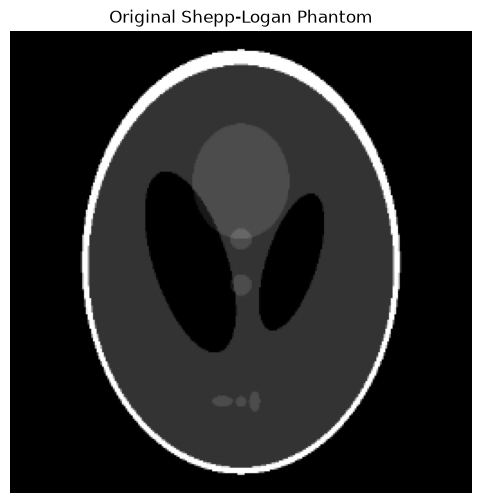

In [2]:
phantom = create_shepp_logan(size=256)

print(f"Image shape: {phantom.shape}")
print(f"Data type: {phantom.dtype}")
print(f"Minimum intensity: {phantom.min():.4f}")
print(f"Maximum intensity: {phantom.max():.4f}")

plt.figure(figsize=(6, 6))
plt.imshow(phantom, cmap="gray")
plt.title("Original Shepp-Logan Phantom")
plt.axis("off")
plt.show()

## 2. Convert the image to unsigned 16-bit integers

The phantom uses floating-point values. Our current DICOM writer expects unsigned 16-bit integer pixels, so we scale the image to the range 0–65535 before saving it.

In [3]:
phantom_uint16 = np.round(
    np.clip(phantom, 0.0, 1.0) * 65535
).astype(np.uint16)

print(f"Data type: {phantom_uint16.dtype}")
print(f"Minimum pixel value: {phantom_uint16.min()}")
print(f"Maximum pixel value: {phantom_uint16.max()}")

Data type: uint16
Minimum pixel value: 0
Maximum pixel value: 65535


## 3. Write the DICOM file

We save the synthetic image in a dedicated output directory. The file contains pixel data and basic synthetic metadata.

In [4]:
output_dir = Path("../../data/dicom")
output_path = output_dir / "synthetic_phantom.dcm"

write_secondary_capture(
    image=phantom_uint16,
    output_path=output_path,
)

print(f"DICOM saved to: {output_path.resolve()}")
print(f"File exists: {output_path.exists()}")
print(f"File size: {output_path.stat().st_size:,} bytes")

DICOM saved to: /Users/isabe/Documents/MedImaging-XAI/data/dicom/synthetic_phantom.dcm
File exists: True
File size: 131,894 bytes


## 4. Read the DICOM file

We load the file and inspect its image dimensions, pixel representation, modality, and synthetic patient identifier.

In [5]:
restored_pixels, dataset = read_dicom_image(output_path)

print(f"Modality: {dataset.Modality}")
print(f"Rows: {dataset.Rows}")
print(f"Columns: {dataset.Columns}")
print(f"Photometric interpretation: {dataset.PhotometricInterpretation}")
print(f"Bits allocated: {dataset.BitsAllocated}")
print(f"Patient ID: {dataset.PatientID}")
print(f"Restored array shape: {restored_pixels.shape}")
print(f"Restored data type: {restored_pixels.dtype}")

Modality: OT
Rows: 256
Columns: 256
Photometric interpretation: MONOCHROME2
Bits allocated: 16
Patient ID: SYNTHETIC001
Restored array shape: (256, 256)
Restored data type: uint16


## 5. Verify pixel preservation

We compare the restored DICOM pixels with the integer image that was written. An exact match demonstrates that the pixel data survived this write/read cycle.

In [6]:
pixels_match = np.array_equal(phantom_uint16, restored_pixels)

print(f"Pixel arrays match exactly: {pixels_match}")

assert pixels_match, "The restored DICOM pixels differ from the original integer image."
assert restored_pixels.shape == phantom_uint16.shape
assert dataset.Rows == phantom_uint16.shape[0]
assert dataset.Columns == phantom_uint16.shape[1]

Pixel arrays match exactly: True


## 6. Visualize the restored image

We display the original floating-point phantom and the image recovered from DICOM. The visual structures should be the same, although the restored image has integer-valued intensities.

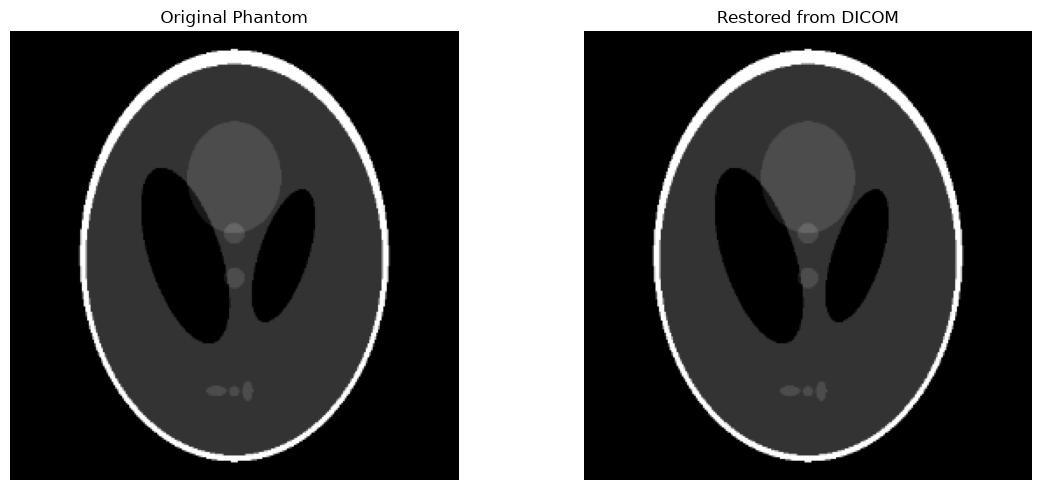

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(phantom, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original Phantom")
axes[0].axis("off")

axes[1].imshow(restored_pixels, cmap="gray", vmin=0, vmax=65535)
axes[1].set_title("Restored from DICOM")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Conclusions

The synthetic image was written to a DICOM Secondary Capture file and read back successfully.

The restored pixel array matches the integer image used for writing, and the image dimensions and selected metadata fields were preserved.

The floating-point phantom was scaled to unsigned 16-bit integers before storage. This experiment validates a basic DICOM write/read workflow; it does not establish clinical suitability or full DICOM conformance.

In [8]:
restored_normalized = restored_pixels.astype(np.float32) / 65535.0

quantization_error = np.abs(phantom - restored_normalized)

print(f"Maximum absolute error: {quantization_error.max():.8f}")
print(f"Mean absolute error: {quantization_error.mean():.8f}")

Maximum absolute error: 0.00000763
Mean absolute error: 0.00000024
